# 1 · A Tour of the Novelty Reviewer Dataset

The dataset links **37,899 ICLR and NeurIPS submissions (2022–2025)** to the novelty judgments of their
**102,021 official reviews**. For every submission it provides:

* the title, abstract and all official reviews with their typed scores,
* verbatim **novelty excerpts** extracted from the reviews,
* a paper-level **Expert-Consensus Novelty Alignment (ECNA)**: a score in {-1, 0, 1, 2} with a justification and a
  detailed assessment.

This notebook loads the data, explains a record, and explores the statistics. It runs on a CPU in a few minutes.

In [ ]:
# Install the package (run once). In Colab, clone the repository first:
# !git clone https://github.com/m2l-lab/Novelty-Reviewer && cd Novelty-Reviewer
# !pip install -q -e "Novelty-Reviewer[notebooks]"

In [1]:
import os

import datasets
import matplotlib.pyplot as plt
import pandas as pd

from novelty_reviewer import NOVELTY_LABELS, eval_subset, load_novelty_dataset, openreview_url, reviews_frame

datasets.disable_progress_bars()
pd.set_option("display.max_colwidth", 120)
# None loads from the Hugging Face Hub; a path loads a local copy of the release folder.
DATASET_PATH = os.environ.get("NOVELTY_DATASET_PATH")

## Loading the data

`load_novelty_dataset` returns a Hugging Face `DatasetDict` with the train/test split used in the paper.

In [2]:
ds = load_novelty_dataset(path=DATASET_PATH)
ds

DatasetDict({
    test: Dataset({
        features: ['paper_id', 'title', 'venue', 'year', 'split', 'in_eval_subset', 'abstract', 'num_reviews', 'reviews', 'review_template', 'novelty_excerpts', 'novelty_extraction_raw', 'novelty_score', 'novelty_score_justification', 'novelty_detailed_assessment', 'novelty_summary'],
        num_rows: 6488
    })
    train: Dataset({
        features: ['paper_id', 'title', 'venue', 'year', 'split', 'in_eval_subset', 'abstract', 'num_reviews', 'reviews', 'review_template', 'novelty_excerpts', 'novelty_extraction_raw', 'novelty_score', 'novelty_score_justification', 'novelty_detailed_assessment', 'novelty_summary'],
        num_rows: 31411
    })
})

Each record is one submission. The columns group into submission metadata, reviews, novelty extractions and the ECNA assessment:

In [3]:
pd.DataFrame({"column": list(ds["train"].features), "type": [str(f)[:90] for f in ds["train"].features.values()]})

,column,type
0,paper_id,Value('string')
1,title,Value('string')
2,venue,Value('string')
3,year,Value('int16')
4,split,Value('string')
5,in_eval_subset,Value('bool')
6,abstract,Value('string')
7,num_reviews,Value('int8')
8,reviews,"List({'review_text': Value('string'), 'clarity': Value('int8'), 'confidence': Value('int8'"
9,review_template,Value('string')


## Anatomy of a record

In [4]:
record = ds["test"].filter(lambda r: r["novelty_score"] == 0 and len(r["novelty_excerpts"]) >= 3).select([0])[0]

print(record["title"])
print(openreview_url(record["paper_id"]), "|", record["venue"], record["year"], "|", record["num_reviews"], "reviews\n")
print("ECNA score:", record["novelty_score"], f"({NOVELTY_LABELS[record['novelty_score']]})\n")
print("Justification:", record["novelty_score_justification"], "\n")
print("Novelty excerpts from the reviews:")
for excerpt in record["novelty_excerpts"][:5]:
    print(" •", excerpt)

Fast Differentiable Matrix Square Root
https://openreview.net/forum?id=-AOEi-5VTU8 | ICLR 2022 | 3 reviews

ECNA score: 0 (Limited novelty)

Justification: The paper presents a combination of existing methods to improve the efficiency of matrix square root computation in deep learning. The work builds on established approaches, such as Taylor expansion and Pade approximation, and extends them to the matrix domain. However, the contributions remain largely incremental, with significant overlap with prior work. 

Novelty excerpts from the reviews:
 • The idea of solving the Lyapunov equation based on matrix sign function and Newton-Schulz iteration seems interesting, which avoids huge memory consumption of the Kronecker product in the original closed-form solution and requirement of Schulz decomposition in Bartels-Stewart algorithm.
 • This paper proposes some strategies to reduce number of matrix multiplications both forward and backward propagations, aiming to improve the efficiency of

Every review keeps its full text and the numerical scores of the venue's review form:

In [5]:
review = record["reviews"][0]
print({k: v for k, v in review.items() if k != "review_text" and v is not None})
print(review["review_text"][:800], "...")

{'confidence': 4, 'correctness': 4, 'empirical_novelty_and_significance': 3, 'rating': 8, 'technical_novelty_and_significance': 3}
# Review

## Summary Of The Paper
The paper addresses the problem of computing the matrix square root of a positive semidefinite matrix and computing the gradient of the matrix square root, so they can be used as a forward pass and a backward pass in a deep learning framework. 

The paper has two separate contributions. In the forward pass, two approximation methods are introduced, Matrix Taylor Polynomial (MTP) and Matrix Pade Approximant (MPA). These are straight-forward generalisations of the scalar power series of, and the scalar Pade approximant to, the function $(1-z)^{1/2}$, to matrices.

In the backward pass, computing the gradient is viewed as a special case of the Sylvester equation, also known as the continuous Lyapunov equation, and is solved using a Newton-Schulz iteration fir ...


## Composition by venue and year

In [6]:
meta = pd.concat([ds[s].select_columns(["paper_id", "venue", "year", "split", "num_reviews", "novelty_score",
                                        "in_eval_subset"]).to_pandas() for s in ds])
composition = meta.groupby(["venue", "year"]).agg(papers=("paper_id", "size"), reviews=("num_reviews", "sum")).unstack(0)
composition.loc["total"] = composition.sum()
composition

papers         reviews        
venue   ICLR NeurIPS    ICLR NeurIPS
year                                
2022    2420    2543    6056    5587
2023    3431    3108    7908    8131
2024    6644    3819   16102    9347
2025   10474    5460   26842   22048
total  22969   14930   56908   45113

## Distribution of novelty scores

Most submissions are judged moderately novel; highly novel and derivative work are both rare.

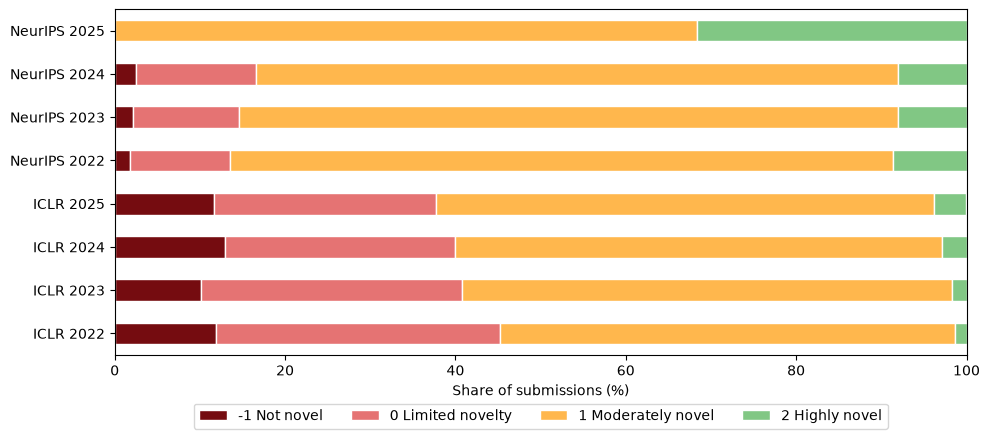

In [7]:
shares = (meta.dropna(subset=["novelty_score"])
          .assign(venue_year=lambda d: d.venue + " " + d.year.astype(str))
          .groupby("venue_year").novelty_score.value_counts(normalize=True).unstack() * 100)
colors = {-1: "#750C10", 0: "#E57373", 1: "#FFB74D", 2: "#81C784"}
ax = shares.plot.barh(stacked=True, figsize=(10, 4.5), color=[colors[c] for c in shares.columns], edgecolor="white")
ax.legend([f"{k} {v}" for k, v in NOVELTY_LABELS.items()], ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_xlabel("Share of submissions (%)"); ax.set_ylabel(""); ax.set_xlim(0, 100)
plt.tight_layout()

In [8]:
meta.novelty_score.value_counts().sort_index().rename(index=NOVELTY_LABELS).to_frame("papers")

,papers
novelty_score,
Not novel,2924
Limited novelty,7606
Moderately novel,24177
Highly novel,3183


## Working with reviews

`reviews_frame` flattens the dataset into one row per review.

In [9]:
reviews = pd.concat([reviews_frame(ds[s]) for s in ds], ignore_index=True)
print(f"{len(reviews):,} reviews")
reviews[["paper_id", "venue", "year", "rating", "confidence", "contribution", "originality"]].head()

102,021 reviews


,paper_id,venue,year,rating,confidence,contribution,originality
0,-3Qj7Jl6UP5,ICLR,2022,3.0,4.0,NaN,NaN
1,-3Qj7Jl6UP5,ICLR,2022,3.0,4.0,NaN,NaN
2,-AOEi-5VTU8,ICLR,2022,8.0,4.0,NaN,NaN
3,-AOEi-5VTU8,ICLR,2022,8.0,5.0,NaN,NaN
4,-AOEi-5VTU8,ICLR,2022,8.0,4.0,NaN,NaN


## Do ECNA labels agree with reviewers' own novelty scores?

Several review forms contain a score that directly concerns novelty: *technical novelty and significance* (ICLR 2022–23),
*contribution* (ICLR 2024–25, NeurIPS 2022–24) and *originality* (NeurIPS 2025). Their correlation with the ECNA labels
is a consistency check. It is not fully independent: the aggregation model reads the full reviews, which include these scores.

In [10]:
from scipy.stats import spearmanr

sub_scores = ["technical_novelty_and_significance", "contribution", "originality"]
per_paper = reviews.groupby("paper_id")[sub_scores + ["rating"]].mean().join(
    meta.set_index("paper_id")[["venue", "year", "novelty_score"]])

rows = []
for score in sub_scores + ["rating"]:
    d = per_paper.dropna(subset=[score, "novelty_score"])
    rho, p = spearmanr(d[score], d.novelty_score)
    rows.append({"reviewer score": score, "papers": len(d), "spearman ρ with ECNA": round(rho, 3), "p-value": f"{p:.1e}"})
pd.DataFrame(rows)

,reviewer score,papers,spearman ρ with ECNA,p-value
0,technical_novelty_and_significance,5851,0.626,0.0e+00
1,contribution,26588,0.522,0.0e+00
2,originality,5451,0.154,2.1e-30
3,rating,32439,0.504,0.0e+00


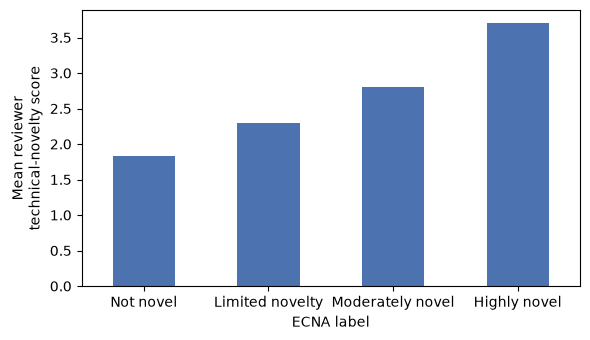

In [11]:
d = per_paper.dropna(subset=["technical_novelty_and_significance", "novelty_score"])
ax = d.groupby("novelty_score").technical_novelty_and_significance.mean().rename(index=NOVELTY_LABELS).plot.bar(
    color="#4C72B0", figsize=(6, 3.5), rot=0)
ax.set_ylabel("Mean reviewer\ntechnical-novelty score"); ax.set_xlabel("ECNA label")
plt.tight_layout()

## Splits and the evaluation subset

The paper evaluates on 500 test papers, marked by `in_eval_subset`. Use `eval_subset` to reproduce it.

In [12]:
print(meta.groupby("split").size().to_dict())
evaluation = eval_subset(ds["test"])
print(f"evaluation subset: {evaluation.num_rows} papers")
evaluation.to_pandas().novelty_score.value_counts().sort_index().rename(index=NOVELTY_LABELS)

{'test': 6488, 'train': 31411}


evaluation subset: 500 papers


novelty_score
Not novel            50
Limited novelty     108
Moderately novel    318
Highly novel         24
Name: count, dtype: int64

## Exporting

The dataset converts to pandas, JSON Lines or CSV:

```python
ds["test"].to_pandas()
ds["test"].to_json("test.jsonl")
```

Full paper texts are not redistributed. Download a paper with `novelty_reviewer.download_openreview_pdf(paper_id)`
and convert it with `novelty_reviewer.pdf.pdf_to_markdown` (see notebook 2).